# Étape B : filtrage du corpus

**Objectif :** ne garder que les avis utiles à l'analyse, puis leur ajouter les informations du logement.

On part de `reviews_clean.parquet` (étape A). 

Plan :
1. Même avis copié dans plusieurs logements
2. Longueur minimale
3. Copies dans un même logement
4. Langue : on garde le français
5. Jointure avec les logements
6. Bilan et sauvegarde

Les fonctions sont dans `src/filtrage.py`.

In [1]:
import sys
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append('../src')
import nettoyage as nt
import filtrage as ft

pd.set_option('display.max_colwidth', 120)

df = pd.read_parquet('../data/processed/reviews_clean.parquet')

# nombre d'avis après chaque étape, pour le bilan
bilan = {'étape A (nettoyage)': len(df)}
print(len(df), 'avis')

515927 avis


## 1. Même avis copié dans plusieurs logements

Certains identifiants d'avis (`id`) apparaissent plusieurs fois : c'est le même avis, recopié par Airbnb
sur plusieurs logements d'un même hôtel (ex. les studios "Appart'City"). On n'en garde qu'un exemplaire.

In [2]:
print('identifiants en double :', df['id'].duplicated().sum())

df = df.drop_duplicates(subset='id')
bilan['1. avis copié sur plusieurs logements'] = len(df)
print(len(df), 'avis')

identifiants en double : 1488
514439 avis


## 2. Longueur minimale

Un avis d'un ou deux mots ("parfait", "très bien") ne dit rien sur un aspect du logement
(propreté, emplacement, accueil..). On regarde la distribution du nombre de mots pour fixer un seuil.
Les jetons `emoji_` et `URLEXPR` ne sont pas comptés comme des mots.

count    514439.0
mean         31.8
std          30.3
min           0.0
25%          12.0
50%          23.0
75%          42.0
max         838.0
Name: nb_mots, dtype: float64


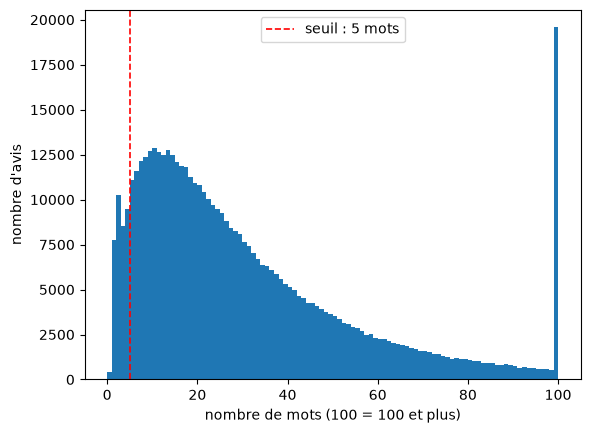

In [3]:
df['nb_mots'] = df['comments_clean'].apply(ft.compter_mots)
print(df['nb_mots'].describe().round(1))

plt.hist(df['nb_mots'].clip(upper=100), bins=100)
plt.axvline(5, color='red', linestyle="--", linewidth=1.2, label='seuil : 5 mots')
plt.xlabel('nombre de mots (100 = 100 et plus)')
plt.ylabel("nombre d'avis")
plt.legend()
plt.show()

In [4]:
for seuil in [3, 5, 10]:
    print(f'avis de moins de {seuil} mots : {(df["nb_mots"] < seuil).mean():.1%}')

print('\nexemples de 4 mots :')
print(df.loc[df['nb_mots'] == 4, 'comments_clean'].head().tolist())

avis de moins de 3 mots : 3.6%
avis de moins de 5 mots : 7.1%
avis de moins de 10 mots : 18.7%

exemples de 4 mots :
['great apartment, well located!', 'clean and centrally located', 'go! go now!!!! ;o)))', 'personne souriante et chaleureuse', 'très bon accueil. merci.']


In [5]:
SEUIL = 5
df = df[df['nb_mots'] >= SEUIL]
bilan['2. moins de 5 mots'] = len(df)
print(len(df), 'avis')

477993 avis


## 3. Copies dans un même logement

Un texte identique deux fois dans le même logement est une copie (avis posté deux fois) : on la supprime.
Les textes répétés **entre logements** sont gardés : ce sont des voyageurs différents.

Cette étape vient **après** le seuil de longueur : avant, la plupart des "copies" étaient des
"parfait" écrits par des voyageurs différents, qu'on aurait supprimés à tort.

In [6]:
copies = df.duplicated(subset=['listing_id', 'comments_clean'])
print('copies dans un même logement :', copies.sum())
print(df.loc[copies, 'comments_clean'].head().tolist())

df = df[~copies]
bilan['3. copies dans un même logement'] = len(df)
print(len(df), 'avis')

copies dans un même logement : 91
["je recommande vivement cette adresse. la chambre et l'appartement sont très agréables et christophe est charmant.", 'la maison est spacieuse, fonctionnel et très confortable, la déco design parfaitement conforme à ce qui est décrit, le descriptif reflète la réalité, pas de mauvaises surprises, que des bonnes!! la bouteille de vin avec les cannelés nous attendez sur la table. dommage que nadine ne puisse nous accueillir pour des raisons médicales. nous avons laissé la voiture dans la rue qui est gratuite sans difficulté stationnement. je recommande ce logement pour son confort et son espace', 'chambre avec sdb indépendante et agréable avec superficie suffisante. hôte très discrète, accueillante et sympathique. frigo et micro onde...bien pratique pour quelques jours et solution proposée pour cuisson .', 'logement très agréable et calme', 'je recommande la chambre de florent']
477902 avis


In [7]:
# textes répétés entre logements : gardés
nt.compter_doublons(df).head(10)

,nb_avis,nb_logements
comments_clean,,
très bon rapport qualité prix,33,33
logement conforme à la description,32,32
très bon séjour je recommande,30,30
"très bon séjour, je recommande",25,25
tout s'est très bien passé,25,25
"très bon séjour, je recommande !",20,20
tout s'est très bien passé.,18,18
logement conforme à la description.,18,18
merci pour votre accueil !,17,17


## 4. Langue : on garde le français

Le corpus mélange plusieurs langues. On ne garde que le français : c'est la langue majoritaire,
et cela permet d'utiliser **un seul modèle spaCy** et **une seule liste de mots vides** aux étapes suivantes.

On utilise `lingua`, fiable sur les textes courts. Les jetons `emoji_...` sont retirés avant la détection :
leurs noms sont en français et feraient passer "great stay 😊" pour du français.

In [8]:
df['langue'] = ft.detecter_langues(df['comments_clean'].tolist())

langues = df['langue'].value_counts()
print((langues / len(df)).head(8).round(3))

langue
FRENCH        0.707
ENGLISH       0.208
SPANISH       0.033
GERMAN        0.022
ITALIAN       0.009
DUTCH         0.008
PORTUGUESE    0.005
RUSSIAN       0.001
Name: count, dtype: float64


In [9]:
# exemples d'avis classés non français, tirés au hasard
df.loc[df['langue'] != 'FRENCH', ['langue', 'comments_clean']].sample(8, random_state=0)

,langue,comments_clean
134176,ENGLISH,location though very convenient for travellers is a little noisy and high traffic area. (have to keep the windows sh...
226163,ENGLISH,place was right in the middle of the city center. lots of places to go and eat also beside the tram station. plenty ...
256653,ENGLISH,very well decorated little house! had a great stay. the owners are super kind. perfect quiet place close to the tram...
42080,SPANISH,muy bien. repetiremos cuando volvamos
142365,ENGLISH,the only note that i have is that the place should have been a little more clean! the linen were full of hairs when ...
361686,ENGLISH,"nice and cosy tiny house, with a super comfy bed, perfect for 1-2 persons. equipped kitchen with a nespresso coffee ..."
476827,SPANISH,todo impecable. buena comunicacion. apartamento propio y funcional
136027,ENGLISH,great location and easy check in/out


In [10]:
df = df[df['langue'] == 'FRENCH']
bilan['4. autres langues que le français'] = len(df)
print(len(df), 'avis')

337787 avis


## 5. Jointure avec les logements

On ajoute à chaque avis des informations sur son logement (`listing_id` = `id` de `listings.csv`) :
le quartier, le type de logement et les notes par catégorie. Elles serviront à comparer les avis
selon le quartier, le type de logement ou la note.

In [11]:
colonnes = ['id', 'neighbourhood_cleansed', 'room_type',
            'review_scores_rating', 'review_scores_accuracy', 'review_scores_cleanliness',
            'review_scores_checkin', 'review_scores_communication',
            'review_scores_location', 'review_scores_value']

logements = pd.read_csv('../data/listings.csv.gz', usecols=colonnes)
logements = logements.rename(columns={'id': 'listing_id', 'neighbourhood_cleansed': 'quartier',
                                      'room_type': 'type_logement'})

df = df.merge(logements, on='listing_id', how='left')
print('avis sans logement trouvé :', df['quartier'].isna().sum())
df.head()

avis sans logement trouvé : 0


,id,listing_id,date,comments_raw,comments_clean,nb_mots,langue,quartier,type_logement,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value
0,208405550,222887,2017-11-01,Cet appartement est tres bien situé dans le centre de bordeaux. Nous avions loué pour 4nuits mais les 2premieres nui...,cet appartement est tres bien situé dans le centre de bordeaux. nous avions loué pour 4nuits mais les 2premieres nui...,103,FRENCH,Bordeaux Sud,Entire home/apt,4.83,4.82,4.76,4.84,4.93,4.75,4.72
1,444560499,222887,2019-04-28,"Merci beaucoup pour l’accueil. L’appartement est superbe, mes amies et moi avons beaucoup aimé la décoration, la vue...","merci beaucoup pour l'accueil. l'appartement est superbe, mes amies et moi avons beaucoup aimé la décoration, la vue...",28,FRENCH,Bordeaux Sud,Entire home/apt,4.83,4.82,4.76,4.84,4.93,4.75,4.72
2,742953863,222887,2021-03-28,Très bel appartement bien situé sur Bordeaux en face de la porte de Bourgogne.<br/>Grande pièce a vivre et belle pet...,très bel appartement bien situé sur bordeaux en face de la porte de bourgogne. grande pièce a vivre et belle petite ...,73,FRENCH,Bordeaux Sud,Entire home/apt,4.83,4.82,4.76,4.84,4.93,4.75,4.72
3,758709018,222887,2021-05-16,Belle découverte et Suzanna est très réactive.,belle découverte et suzanna est très réactive.,7,FRENCH,Bordeaux Sud,Entire home/apt,4.83,4.82,4.76,4.84,4.93,4.75,4.72
4,770446346,222887,2021-06-14,Nous avons passé un très bon séjour ! L'appartement a beaucoup de charme et est très bien équipé. La terrasse est ex...,nous avons passé un très bon séjour ! l'appartement a beaucoup de charme et est très bien équipé. la terrasse est ex...,73,FRENCH,Bordeaux Sud,Entire home/apt,4.83,4.82,4.76,4.84,4.93,4.75,4.72


In [12]:
df.describe()

,id,listing_id,nb_mots,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value
count,3.377870e+05,3.377870e+05,337787.000000,337787.000000,337786.000000,337787.000000,337783.00000,337785.000000,337783.000000,337783.000000
mean,8.853871e+17,3.736203e+17,29.438208,4.805439,4.852519,4.782080,4.89263,4.892803,4.764998,4.731957
std,6.170616e+17,5.344013e+17,24.679384,0.159667,0.127792,0.200259,0.10426,0.114291,0.160466,0.168569
min,1.074751e+06,2.228870e+05,5.000000,1.000000,1.000000,1.000000,1.00000,0.000000,1.000000,1.000000
25%,7.697372e+08,1.985457e+07,13.000000,4.740000,4.810000,4.700000,4.86000,4.860000,4.690000,4.650000
50%,9.904145e+17,4.278553e+07,23.000000,4.840000,4.880000,4.830000,4.92000,4.920000,4.790000,4.760000
75%,1.439802e+18,8.607323e+17,38.000000,4.920000,4.930000,4.930000,4.96000,4.960000,4.880000,4.850000
max,1.778166e+18,1.772610e+18,670.000000,5.000000,5.000000,5.000000,5.00000,5.000000,5.000000,5.000000


## 6. Bilan et sauvegarde

In [13]:
bilan = pd.Series(bilan, name="avis restants").to_frame()
bilan['avis retirés'] = -bilan["avis restants"].diff().fillna(0).astype(int)
bilan

,avis restants,avis retirés
étape A (nettoyage),515927,0
1. avis copié sur plusieurs logements,514439,1488
2. moins de 5 mots,477993,36446
3. copies dans un même logement,477902,91
4. autres langues que le français,337787,140115


In [14]:
df = df.drop(columns=['langue'])
df.to_parquet('../data/processed/reviews_fr.parquet')
print(df.shape)

(337787, 15)
